In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print(df.head())

Saving metro traffic volume datasets in dl.ipynb to metro traffic volume datasets in dl (4).ipynb
Dataset loaded successfully
Shape: (0, 1909)
Empty DataFrame
Columns: [{"cells":[{"cell_type":"markdown", metadata:{}, source:["### Metro Interstate Traffic Volume\n", \n, ### Abstract: Hourly Minneapolis-St Paul, MN traffic volume for westbound I-94. Includes weather and holiday features from 2012-2018.\n, https://archive.ics.uci.edu/ml/datasets/Metro+Interstate+Traffic+Volume\n, \n.1, 1. holiday Categorical US National holidays plus regional holiday, Minnesota State Fair \n, 2. temp Numeric Average temp in kelvin \n, 3. rain_1h Numeric Amount in mm of rain that occurred in the hour \n, 4. snow_1h Numeric Amount in mm of snow that occurred in the hour \n, 5. clouds_all Numeric Percentage of cloud cover \n, 6. weather_main Categorical Short textual description of the current weather \n, 7. weather_description Categorical Longer textual description of the current weather \n, 8. date_time Da

In [22]:
import pandas as pd
import numpy as np


csv_path = 'Metro_Interstate_Traffic_Volume.csv'
df = pd.read_csv(csv_path)

df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")

features = [
    "traffic_volume", "temp", "rain_1h",
    "snow_1h", "clouds_all"
]

for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["date_time", "traffic_volume"])
df = df.sort_values("date_time")
df = df.drop_duplicates(subset="date_time").reset_index(drop=True)


df["temp"] = df["temp"] - 273.15


df.loc[df["temp"] < -100, "temp"] = np.nan
df.loc[df["rain_1h"] > 2000, "rain_1h"] = np.nan

df["hour"] = df["date_time"].dt.hour
df["weekday"] = df["date_time"].dt.dayofweek
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

features = [
    "traffic_volume", "temp", "rain_1h",
    "snow_1h", "clouds_all",
    "hour_sin", "hour_cos", "weekday"
]

df[features] = df[features].replace([np.inf, -np.inf], np.nan)
df[features] = df[features].ffill()

df = df.dropna(subset=features).reset_index(drop=True)

print("Preprocessing completed successfully!")
print("Shape of DataFrame:", df.shape)
print(df[["date_time"] + features].head())

Preprocessing completed successfully!
Shape of DataFrame: (40575, 13)
            date_time  traffic_volume   temp  rain_1h  snow_1h  clouds_all  \
0 2012-10-02 09:00:00            5545  15.13      0.0      0.0          40   
1 2012-10-02 10:00:00            4516  16.21      0.0      0.0          75   
2 2012-10-02 11:00:00            4767  16.43      0.0      0.0          90   
3 2012-10-02 12:00:00            5026  16.98      0.0      0.0          90   
4 2012-10-02 13:00:00            4918  17.99      0.0      0.0          75   

       hour_sin  hour_cos  weekday  
0  7.071068e-01 -0.707107        1  
1  5.000000e-01 -0.866025        1  
2  2.588190e-01 -0.965926        1  
3  1.224647e-16 -1.000000        1  
4 -2.588190e-01 -0.965926        1  


In [23]:
from sklearn.preprocessing import MinMaxScaler


data_subset = df.iloc[-5000:].copy().reset_index(drop=True)


scale_features = ['traffic_volume', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'hour_sin', 'hour_cos', 'weekday']
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data_subset[scale_features])

def create_sequences(data, window_size=24):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size])
        y.append(data[i+window_size, 0])
    return np.array(X), np.array(y)

window_size = 24
X, y = create_sequences(scaled_data, window_size)


split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

Training input shape: (3980, 24, 8)
Testing input shape: (996, 24, 8)


In [25]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout


model = Sequential([
    LSTM(64, activation='tanh', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
    Dropout(0.2),
    LSTM(32, activation='tanh'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()

history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 24, 64)         │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,649 (123.63 KB)

 Trainable params: 31,649 (123.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0546 - val_loss: 0.0153
Epoch 2/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0212 - val_loss: 0.0127
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0146 - val_loss: 0.0067
Epoch 4/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0119 - val_loss: 0.0060
Epoch 5/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0099 - val_loss: 0.0051
Epoch 6/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0092 - val_loss: 0.0051
Epoch 7/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 0.0092 - val_loss: 0.0050
Epoch 8/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0081 - val_loss: 0.0047
Epoch 9/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0079 - val_loss: 0.0057
Epoch 10/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0070 - val_loss: 0.0037
Epoch 11/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0070 - val_loss: 0.0041
Epoch 12/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 

In [26]:

predictions_scaled = model.predict(X_test)


dummy_pred = np.zeros((len(predictions_scaled), len(scale_features)))
dummy_pred[:, 0] = predictions_scaled.flatten()
predictions = scaler.inverse_transform(dummy_pred)[:, 0]

dummy_actual = np.zeros((len(y_test), len(scale_features)))
dummy_actual[:, 0] = y_test
actuals = scaler.inverse_transform(dummy_actual)[:, 0]

mae = mean_absolute_error(actuals, predictions)
rmse = np.sqrt(mean_squared_error(actuals, predictions))

print(f"Mean Absolute Error (MAE): {mae:.2f} vehicles")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} vehicles")

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Mean Absolute Error (MAE): 309.84 vehicles
Root Mean Squared Error (RMSE): 455.81 vehicles


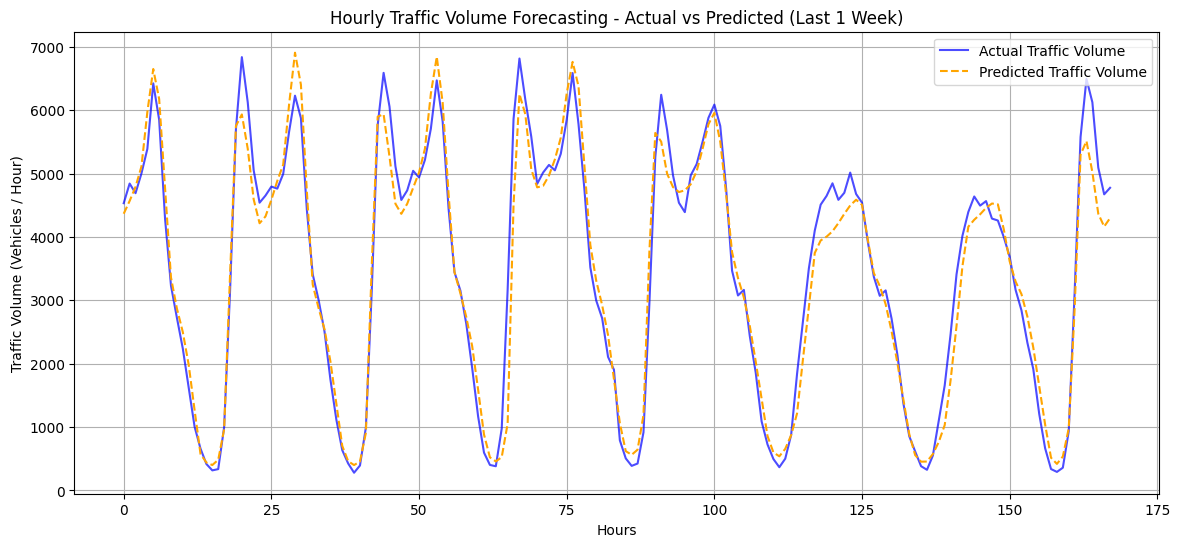

In [27]:

plt.figure(figsize=(14, 6))
plt.plot(actuals[:168], label='Actual Traffic Volume', color='blue', alpha=0.7)
plt.plot(predictions[:168], label='Predicted Traffic Volume', color='orange', linestyle='--')
plt.title('Hourly Traffic Volume Forecasting - Actual vs Predicted (Last 1 Week)')
plt.xlabel('Hours')
plt.ylabel('Traffic Volume (Vehicles / Hour)')
plt.legend()
plt.grid(True)
plt.show()

In [29]:

sample_input_seq = X_test[0:1]


predicted_scaled = model.predict(sample_input_seq)


dummy_pred = np.zeros((1, len(scale_features)))
dummy_pred[0, 0] = predicted_scaled[0, 0]
predicted_vehicles = scaler.inverse_transform(dummy_pred)[0, 0]


actual_scaled = y_test[0]
dummy_actual = np.zeros((1, len(scale_features)))
dummy_actual[0, 0] = actual_scaled
actual_vehicles = scaler.inverse_transform(dummy_actual)[0, 0]

print("=== USER INPUT ===")
print(f"Sequence of 24 consecutive hourly records fed into the model (shape: {sample_input_seq.shape})")
print("Each hour contains 8 scaled features: [traffic_volume, temp, rain, snow, clouds, hour_sin, hour_cos, weekday]")

print("\n=== MODEL OUTPUT ===")
print(f"Predicted Traffic Volume for the next hour: {int(np.round(predicted_vehicles))} vehicles/hour")
print(f"Actual Traffic Volume for the next hour: {int(np.round(actual_vehicles))} vehicles/hour")
print(f"Prediction Error: {abs(int(np.round(predicted_vehicles)) - int(np.round(actual_vehicles)))} vehicles")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
=== USER INPUT ===
Sequence of 24 consecutive hourly records fed into the model (shape: (1, 24, 8))
Each hour contains 8 scaled features: [traffic_volume, temp, rain, snow, clouds, hour_sin, hour_cos, weekday]

=== MODEL OUTPUT ===
Predicted Traffic Volume for the next hour: 4366 vehicles/hour
Actual Traffic Volume for the next hour: 4532 vehicles/hour
Prediction Error: 166 vehicles
